In [1]:
# Necessary imports.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import heating_functions as hf
import matplotlib
from scipy.interpolate import LinearNDInterpolator

# plotting defaults.
onecolwidth=6.78
twocolwidth=14.12
fontsize=16


# Generating figure 1.

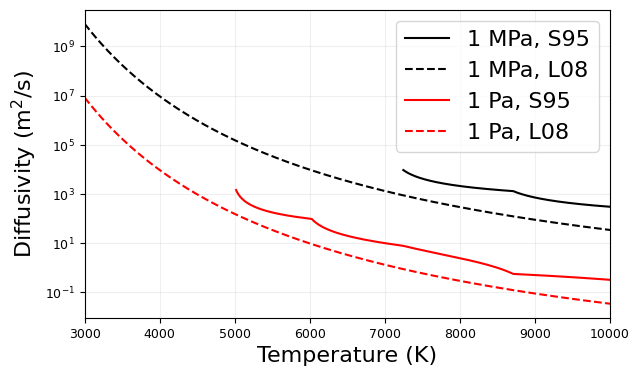

In [2]:

plt.figure(figsize=(onecolwidth, 4))

t = np.linspace(3000, 10000, 1000)
r = hf.diffusivity_hhe_si(t, 10**6)
r08 = hf.diffusivity_L08(t, 10**6)

plt.plot(t, r,color="black", label = "1 MPa, S95")
plt.plot(t, r08,"--",color="black", label = "1 MPa, L08")

plt.yscale("log")
#plt.xscale("log")

r = hf.diffusivity_hhe_si(t, 1)
r08 = hf.diffusivity_L08(t, 1)

plt.plot(t, r,color="red", label="1 Pa, S95")
plt.plot(t, r08,"--",color="red", label="1 Pa, L08")

plt.xlabel("Temperature (K)",fontsize=fontsize)
plt.ylabel("Diffusivity (m$^2$/s)", fontsize=fontsize)
#plt.title("Resistivity of H/He Atmosphere")
plt.legend(fontsize=fontsize)
plt.grid(alpha=0.2)
plt.xlim(np.min(t), np.max(t))
plt.savefig("diffusivity_vs_temperature.png", dpi=300, bbox_inches="tight")


# Finding the temperature-pressure profile with GASTLI for our default case.

In [204]:
porb_default = 3 #d
mp_default = 1 # MJup
tstar_default=5778 #K
mstar_default=1 # msolar
rstar_default = 1 #rsolar

a_default = ((porb_default/365)**2 * mstar_default)**(1/3) 
teq_default = tstar_default * np.sqrt(rstar_default*hf.RSOLAR/(a_default*hf.AU)) * (1/4)**(1/4)


rp, tprofile, pprofile = hf.generate_profile(mpl=mp_default,teq=teq_default, cmf=0.01, log_feh=0, co=0.55, tint=100, fixed_radius=None)

Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
 [i] Allowed maximum number of iterations reached.
 

Convergence reached in surface temperature and bulk radius



# Generating figure 2.

In [82]:
rp_default = hf.RJUP # m
rotper_default = 2 #d
bsurf_default = 1000 # G
alpha_default = np.pi/2 # radians

# we just want the profile, so only calculate at one time
ts = np.array([0])

_, _, _, r_profile1, pind_profile1, eta_profile1 = hf.find_power(ts, p=porb_default, alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, l=1)
_, _, _, r_profile2, pind_profile2, eta_profile2 = hf.find_power(ts, p=porb_default, alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, l=2)


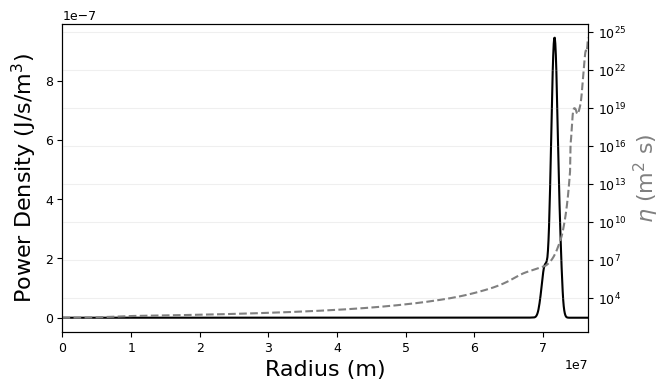

In [84]:
fig, axs=plt.subplots(1, figsize=(onecolwidth, 4))
axs.plot(r_profile2, pind_profile2,color="black")
axs.set_xlabel("Radius (m)", fontsize=fontsize)
axs.set_ylabel("Power Density (J/s/m$^3$)", fontsize=fontsize)
ax2=axs.twinx()

ax2.plot(r_profile2, eta_profile2, "--",color="gray")
ax2.set_yscale("log")
ax2.set_ylabel("$\eta$ (m$^2$ s)", fontsize=fontsize, color="gray")
plt.xlim(0,np.max(r_profile2))

plt.grid(alpha=0.2)
plt.savefig("dissipation_location", dpi=300, bbox_inches="tight")


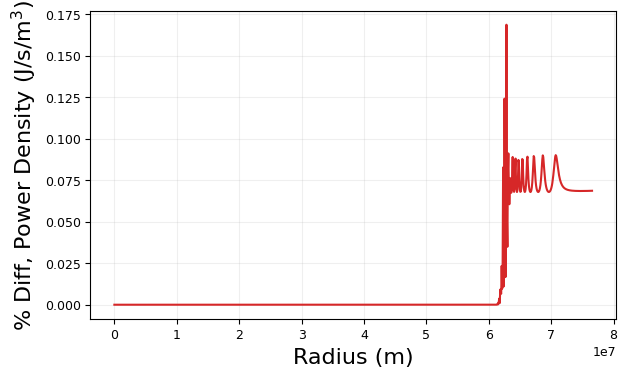

In [92]:
fig, axs=plt.subplots(1, figsize=(onecolwidth, 4))
axs.plot(r_profile1, (pind_profile2-pind_profile1)/pind_profile2*100,color="C3")

axs.set_xlabel("Radius (m)", fontsize=fontsize)
axs.set_ylabel("% Diff, Power Density (J/s/m$^3$)", fontsize=fontsize)


plt.grid(alpha=0.2)
#plt.savefig("dissipation_location", dpi=300, bbox_inches="tight")


# Checking differences between pind when considering harmonics up to l=1 or l=2.

In [41]:
porb_vals = np.linspace(0.1, 2, 20) #d
a_vals = ((porb_vals/365)**2 * mstar_default)**(1/3) 
teq_vals = tstar_default * np.sqrt(rstar_default*hf.RSOLAR/(a_vals*hf.AU)) * (1/4)**(1/4)

ps_l1=np.zeros(len(porb_vals))
ps_l2=np.zeros(len(porb_vals))

for i in range(len(porb_vals)):

    rp_val, tprofile_val, pprofile_val = hf.generate_profile(mpl=mp_default,teq=teq_vals[i], cmf=0.01, log_feh=0, co=0.55, tint=100, fixed_radius=None)
    ps_l1[i], _, _, _, _, _ = hf.find_power(ts, p=porb_vals[i], alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp_val, pregen_tprofile=tprofile_val, pregen_pprofile=pprofile_val, l=1)
    ps_l2[i], _, _, _, _, _ = hf.find_power(ts, p=porb_vals[i], alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp_val, pregen_tprofile=tprofile_val, pregen_pprofile=pprofile_val, l=2)


Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Convergence reached in surface temperature and bulk radius



Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)


Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating [i] Allowed maximum number of iterations reached.
 

Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Convergence reached in surface temperature and bulk radius



Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)


Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating [i] Allowed maximum number of iterations reached.
 

Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
 [i] Allowed maximum number of iterations reached.
 

Convergence reached in surface temperature and bulk radius



Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)


... (30 outputs left out)

Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Surface gravity is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Surface gravity is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium

Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)


Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
 [i] Allowed maximum number of iterations reached.
 

Convergence reached in surface temperature and bulk radius



Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)


invalid value encountered in divide


Text(0, 0.5, '% Diff, Power Density (J/s/m$^3$)')

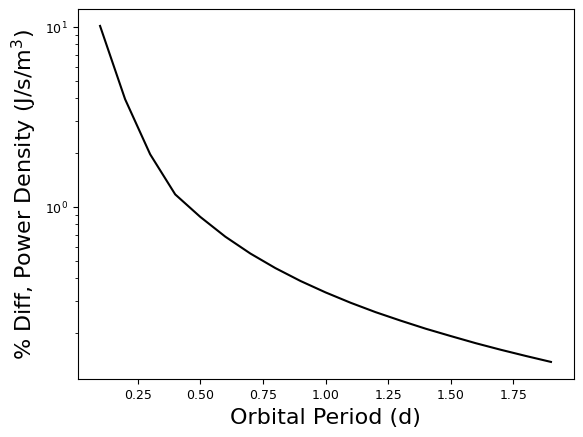

In [97]:
plt.plot(porb_vals, (ps_l2-ps_l1)/ps_l1 * 100, color="black")
plt.yscale("log")

plt.xlabel("Orbital Period (d)", fontsize=fontsize)
plt.ylabel("% Diff, Power Density (J/s/m$^3$)", fontsize=fontsize)


# Generating Figure 3.

In [103]:
bsurfs=np.logspace(-1, 6, 30, base=10)
ps_m=np.zeros(len(bsurfs))
ts = np.linspace(0, porb_default*24*3600)

for i in tqdm(range(len(bsurfs))):
    pinds_m, _, _, _, _, _= hf.find_power(ts, p=porb_default, alpha=alpha_default, bsurf=bsurfs[i], rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, l=2)
    ps_m[i]=np.mean(pinds_m)

100%|███████████████████████████████████████████| 30/30 [00:01<00:00, 19.82it/s]


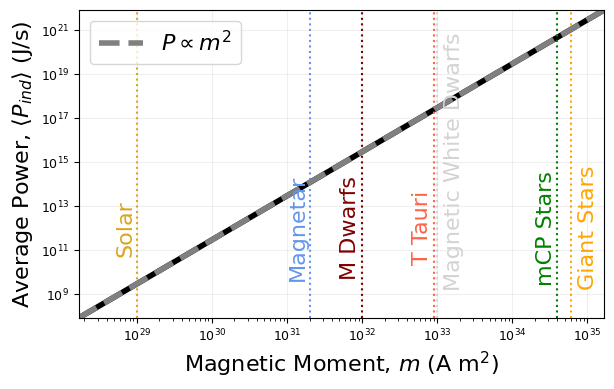

In [104]:
mms= bsurfs/10**4*2*np.pi/hf.MU0 * (6.957*10**8)**3
plt.figure(figsize=(onecolwidth, 4))

plt.plot(mms, ps_m,lw=4, color="black")
plt.yscale("log")
plt.xscale("log")



from scipy.optimize import curve_fit
def func(x, a):
    return x**2 * a
    

popt, pcov = curve_fit(func, mms, ps_m, p0=(10**-46))

msolar=1e29
mtt=9e32
mm=2e31
mmcp=4e34
mg=6e34

mmd=1e32
mw=1e33


plt.axvline(msolar, ls=":", color="goldenrod")
plt.text(msolar*0.7, 1e12, "Solar", color="goldenrod", ha="center", va="center", rotation=90, fontsize=fontsize)
plt.axvline(mtt, color="tomato", ls=":")
plt.text(mtt*0.7, 1e12, "T Tauri", color="tomato", ha="center", va="center", rotation=90, fontsize=fontsize)
plt.axvline(mm, color="cornflowerblue", ls=":")
plt.text(mm*0.7, 1e12, "Magnetar", color="cornflowerblue", ha="center", va="center", rotation=90, fontsize=fontsize)

plt.axvline(mmcp, color="green", ls=":")
plt.text(mmcp*0.7, 1e12, "mCP Stars", color="green", ha="center", va="center", rotation=90, fontsize=fontsize)

plt.axvline(mmd, color="maroon", ls=":")
plt.text(mmd*0.7, 1e12, "M Dwarfs", color="maroon", ha="center", va="center", rotation=90, fontsize=fontsize)

plt.axvline(mw, color="lightgray", ls=":")
plt.text(mw*1.7, 1e15, "Magnetic White Dwarfs", color="lightgray", ha="center", va="center", rotation=90, fontsize=fontsize)


plt.axvline(mg, color="orange", ls=":")
plt.text(mg*1.7, 1e12, "Giant Stars", color="orange", ha="center", va="center", rotation=90, fontsize=fontsize)


plt.plot(mms, func(mms, *popt), color="gray", ls="--", lw=4,label=("$P \propto m^{2}$"))
plt.xlabel("Magnetic Moment, $m$ (A m$^2$)", fontsize=fontsize)
plt.ylabel("Average Power, $\langle P_{ind} \\rangle$ (J/s)", fontsize=fontsize)
plt.legend(fontsize=fontsize)
plt.grid(alpha=0.2)
plt.xlim(np.min(mms), np.max(mms))
plt.ylim(np.min(ps_m), np.max(ps_m))
plt.savefig("m_power.png", dpi=300, bbox_inches="tight")

# Figure 4.

In [105]:


alphas=np.linspace(0, 2*np.pi)
#porb = np.array([0.5, 1, 30, 1000])
ps_a=np.zeros(len(alphas))
ts = np.linspace(0, porb_default*24*3600)

for i in tqdm(range(len(alphas))):
    pinds_a, _, _, _, _, _ = hf.find_power(ts, p=porb_default, alpha=alphas[i], bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, l=2)
    ps_a[i]=np.mean(pinds_a)



100%|███████████████████████████████████████████| 50/50 [00:02<00:00, 19.69it/s]


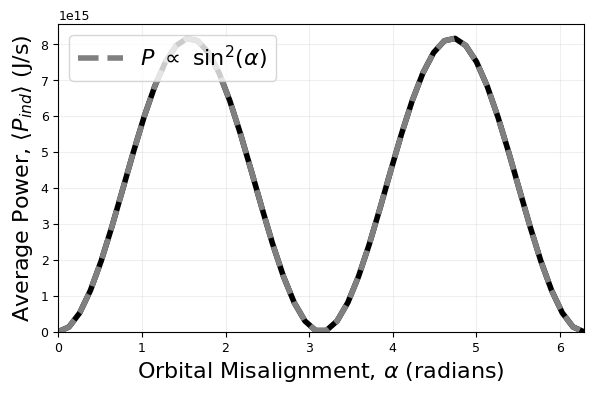

In [106]:
plt.figure(figsize=(onecolwidth, 4))
plt.plot(alphas, ps_a, lw=4,color="black")

plt.xlabel("Orbital Misalignment, $\\alpha$ (radians)", fontsize=fontsize)
plt.ylabel("Average Power, $\langle P_{ind} \\rangle$ (J/s)", fontsize=fontsize)


from scipy.optimize import curve_fit
def func(x, a):
    return np.sin(x)**2 * a
    

popt, pcov = curve_fit(func, alphas, ps_a, p0=(10**18))


plt.plot(alphas, func(alphas, *popt), lw=4,color="gray", ls="--", label="$P$ $\propto$ sin$^2$($\\alpha$)")
plt.legend(fontsize=fontsize, loc="upper left")
plt.grid(alpha=0.2)
plt.xlim(0, 2*np.pi)
plt.ylim(0)
plt.savefig("alpha_power.png", dpi=300, bbox_inches="tight")


# Figure 5.

In [107]:
prot = np.linspace(0.5, 10, 100)
#prot = np.array([1, 2, 4, 5, 6, 7, 8, 9, 10])
ps_w=np.zeros(len(prot))
ts = np.linspace(0, porb_default*24*3600)

for i in tqdm(range(len(prot))):
    pinds_w, _, _, _, _, _ = hf.find_power(ts, p=porb_default, alpha=alpha_default, bsurf=bsurf_default, rotper=prot[i], fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, l=2)
    
    ps_w[i]=np.mean(pinds_w)


100%|█████████████████████████████████████████| 100/100 [00:19<00:00,  5.06it/s]


[8.23202804e-01 9.47844415e+19]


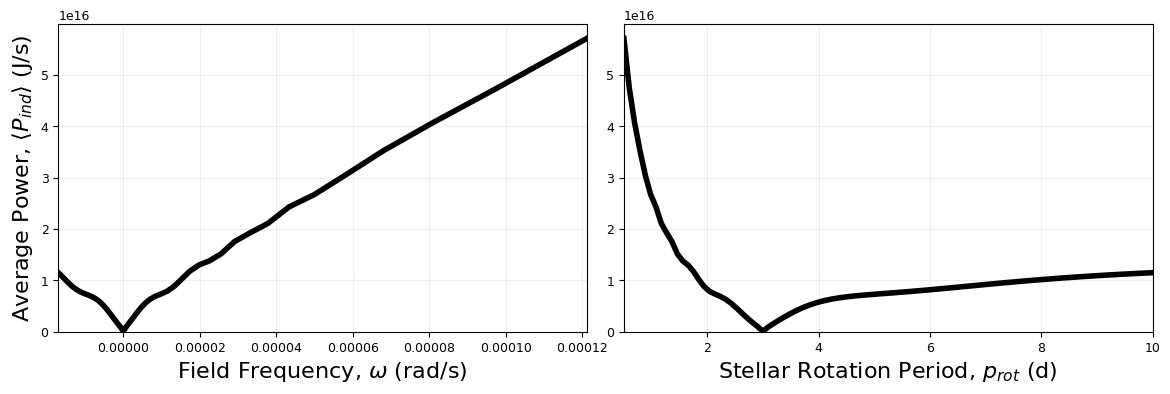

In [108]:

w = 2*np.pi/(prot*24*3600) - 2*np.pi/(3*24*3600)

fig, axs = plt.subplots(1,2 ,figsize=(twocolwidth, 4))
axs[0].plot(w, ps_w, color="black", lw=4)
#plt.xlabel("Stellar Rotation Period, p$_{rot, \star}$", fontsize=16)
axs[0].set_xlabel("Field Frequency, $\omega$ (rad/s)", fontsize=fontsize)
axs[1].set_xlabel("Stellar Rotation Period, $p_{rot}$ (d)", fontsize=fontsize)
axs[1].plot(prot, ps_w, color="black", lw=4)


x=w

from scipy.optimize import curve_fit
def func(x, a,b):
    return x**a * b
    

popt, pcov = curve_fit(func,w[w>0], ps_w[w>0], p0=(0.8, 1e20))
print(popt)



axs[0].grid(alpha=0.2)
axs[1].grid(alpha=0.2)


axs[0].set_xlim(np.min(w), np.max(w))
axs[1].set_xlim(np.min(prot), np.max(prot))
axs[0].set_ylim(0)
axs[1].set_ylim(0)

axs[0].set_ylabel("Average Power, $\langle P_{ind} \\rangle$ (J/s)", fontsize=fontsize)
plt.subplots_adjust(wspace=0.07)
plt.savefig("omega_power.png", dpi=300, bbox_inches="tight")

# Figure 6.

In [109]:
# unfortunately, as porb (and therefore teq) is not constant, we need to recalculate the profile for every instance.
# That means that this will be slow.

porb = np.linspace(0.5, 10, 100)
#porb = np.array([0.5, 1, 30, 1000])
ps_p=np.zeros(len(porb))
rs_p = np.zeros(len(porb))

for i in tqdm(range(len(porb))):
    ts=np.linspace(0, porb[i]*24*3600)
    pinds_p, _, _, rs, _, _ = hf.find_power(ts, p=porb[i], alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, mp=mp_default, use_GASTLI=True, l=2)
    
    ps_p[i]=np.mean(pinds_p)
    rs_p[i] = np.max(rs)


  0%|                                                   | 0/100 [00:00<?, ?it/s]

Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating


  1%|▍                                          | 1/100 [00:04<06:45,  4.09s/it]

 [i] Allowed maximum number of iterations reached.
 

Convergence reached in surface temperature and bulk radius

Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating [i] Allowed maximum number of iterations reached.
 

Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Convergence reached in surface temperature and bulk radius



  2%|▊                                          | 2/100 [00:08<06:49,  4.18s/it]

Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 
Equilibrium temperature is out of atmospheric grid limits. Extrapolating
Equilibrium temperature is out of atmospheric grid limits. Extrapolating

Running interior structure model


... (192 outputs left out)

 99%|█████████████████████████████████████████▌| 99/100 [09:00<00:06,  6.13s/it]


Running interior structure model
 [i] Allowed maximum number of iterations reached.
 

Convergence reached in surface temperature and bulk radius


Running interior structure model
 [i] Allowed maximum number of iterations reached.
 

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 

Running interior structure model
 [i] Allowed maximum number of iterations reached.
 


100%|█████████████████████████████████████████| 100/100 [09:05<00:00,  5.46s/it]


Convergence reached in surface temperature and bulk radius



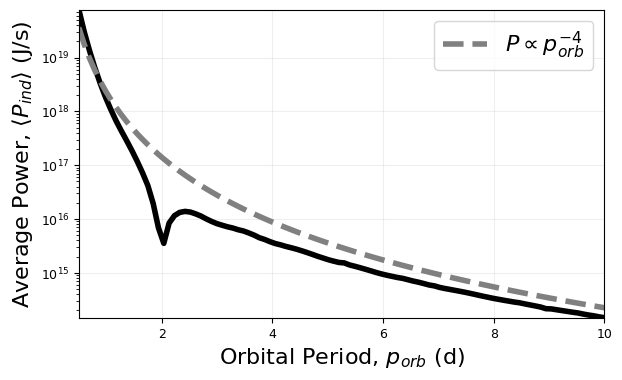

In [110]:
plt.figure(figsize=(onecolwidth, 4))


plt.plot(porb, ps_p, color="black", lw=4)
plt.yscale("log")
plt.xlabel("Orbital Period, $p_{orb}$ (d)", fontsize=fontsize)
plt.ylabel("Average Power, $\langle P_{ind} \\rangle$ (J/s)", fontsize=fontsize)


from scipy.optimize import curve_fit


def func(x, a,):
    return x**-4 * a
    

x = porb
y = porb**-4 * 10**20.3

plt.xlim(np.min(porb), np.max(porb))
plt.ylim(np.min(ps_p), np.max(ps_p))

popt, pcov = curve_fit(func, porb, ps_p, p0=(10**20.3))
plt.grid(alpha=0.2)

plt.plot(x,func(x, *popt)*0.5, color="gray", ls="--", label=("$P \propto p_{orb}^{-4}$"), lw=4)
plt.legend(fontsize=fontsize)
plt.savefig("porb_power.png", dpi=300, bbox_inches="tight")

# Figure 7.

In [127]:
etamults=np.logspace(-7, 7,100, base=10)
ps_eta=np.zeros(len(etamults))

ts=np.linspace(0, porb_default*24*3600)
for i in tqdm(range(len(etamults))):
    pinds_eta, _, _, _, _, _ = hf.find_power(ts, p=porb_default, alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, eta_mult=etamults[i], l=2)
    ps_eta[i]=np.mean(pinds_eta)


100%|█████████████████████████████████████████| 100/100 [00:50<00:00,  2.00it/s]


In [211]:
pind_eta_base, _, _, _, _, _ = hf.find_power(ts, p=porb_default, alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, eta_mult=1, l=2)
pind_eta_base=np.mean(pind_eta_base)

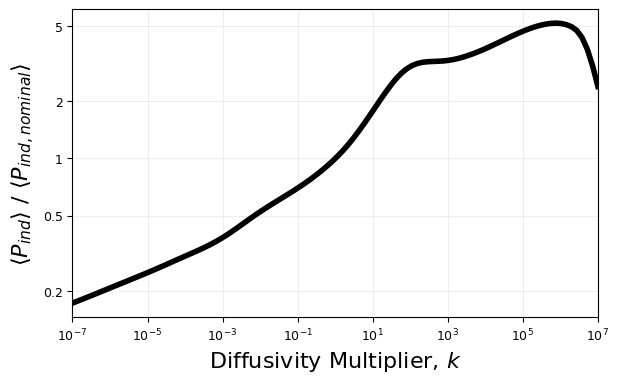

In [232]:
plt.figure(figsize=(onecolwidth, 4))


plt.plot(etamults, ps_eta/pind_eta_base, color="black", lw=4)
plt.xlabel("Diffusivity Multiplier, $k$", fontsize=fontsize)
plt.ylabel("$\langle P_{ind} \\rangle$ / $\langle P_{ind, nominal} \\rangle$", fontsize=fontsize)
plt.xscale("log")
plt.xlim(10**-7, 10**7)
plt.grid(alpha=0.2)
plt.yscale("log")

plt.minorticks_off()
plt.yticks(ticks=[0.2, 0.5, 1, 2, 5], labels=[0.2, 0.5, 1, 2, 5], minor=False)

plt.savefig("eta_power.png", dpi=300, bbox_inches="tight")
#plt.yscale("log")


In [240]:
np.max(ps_eta)/np.min(ps_eta)

29.81395365898066

# Figure 8.

In [129]:
tempmults=np.linspace(0.3, 5.0, 100)
#porb = np.array([0.5, 1, 30, 1000])
ps_temp=np.zeros(len(tempmults))

nt=30
ts=np.linspace(0, porb_default*24*3600)
for i in tqdm(range(len(tempmults))):
    pinds_temp, _, _, _, _, _ = hf.find_power(ts, p=porb_default, alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, temp_mult=tempmults[i], l=2)
    ps_temp[i]=np.mean(pinds_temp)


100%|█████████████████████████████████████████| 100/100 [00:19<00:00,  5.06it/s]


In [216]:
pind_temp_base, _, _, _, _, _ = hf.find_power(ts, p=porb_default, alpha=alpha_default, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile,temp_mult=1, l=2)
pind_temp_base=np.mean(pind_temp_base)

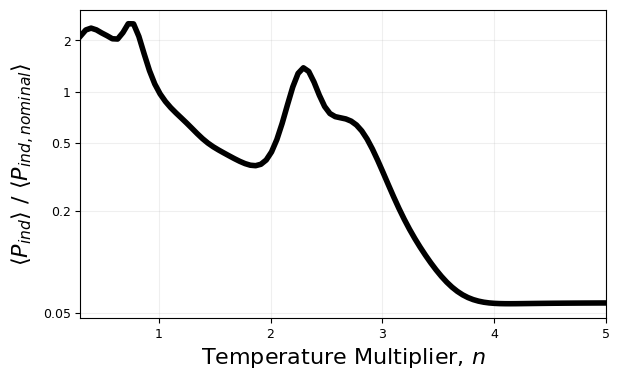

In [239]:
plt.figure(figsize=(onecolwidth, 4))


plt.plot(tempmults, ps_temp/pind_temp_base, color="black", lw=4)

plt.grid(alpha=0.2)

plt.xlim(np.min(tempmults), np.max(tempmults))
plt.grid(alpha=0.2)
plt.yscale("log")
plt.xlabel("Temperature Multiplier, $n$", fontsize=fontsize)
plt.ylabel("$\langle P_{ind} \\rangle$ / $\langle P_{ind, nominal} \\rangle$", fontsize=fontsize)



plt.minorticks_off()
plt.yticks(ticks=[0.05, 0.2, 0.5, 1, 2], labels=[0.05, 0.2, 0.5, 1, 2], minor=False)



plt.savefig("n_power.png", dpi=300, bbox_inches="tight")


# Figure 9.

In [133]:
eccs = np.array([0.0, 0.01, 0.1, 0.3])
alphas = np.array([np.pi/2, np.pi/4, 0])
ts=np.linspace(0, porb_default*24*3600)

ps_ecc_alpha = np.zeros((len(eccs), len(alphas), len(ts)))

for i in range(len(eccs)):
    for j in range(len(alphas)):

        pinds_ecc_alpha, _, _, _, _, _ = hf.find_power(ts,ecc=eccs[i], p=porb_default, alpha=alphas[j], bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile, l=1)
        ps_ecc_alpha[i][j]=pinds_ecc_alpha

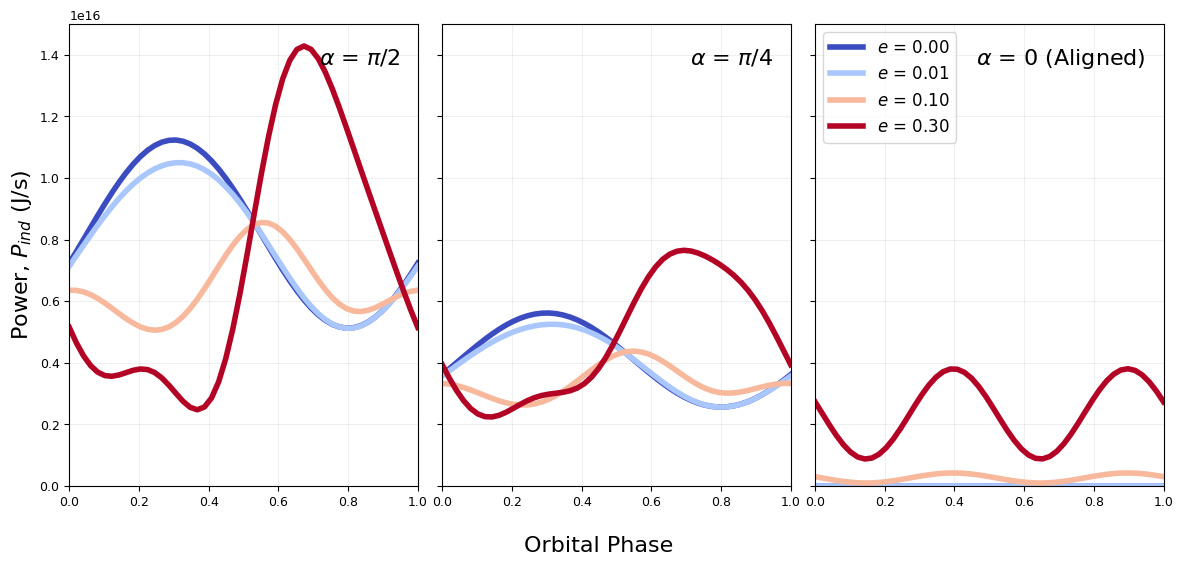

In [134]:
import matplotlib.cm as cm
fig, axs = plt.subplots(1,3, sharex=True, sharey=True, figsize=(twocolwidth, 6))

for i in range(len(eccs)):
    for j in range(len(alphas)):
        axs[j].plot(ts/24/3600/porb_default, ps_ecc_alpha[i][j], color=cm.coolwarm(i/(len(eccs)-1)), lw=4, label="$e$ = {ecc:.2f}".format(ecc=eccs[i]))

    
axs[j].set_ylim(0)
#axs[j].set_xlim(0, 1)

plt.subplots_adjust(wspace=0.07, hspace=0)

axs[0].set_ylabel("Power, $P_{ind}$ (J/s)", fontsize=fontsize)
fig.text(0.5, 0.00, 'Orbital Phase', ha='center', fontsize=fontsize)

axs[0].text(0.95, 0.95, '$\\alpha$ = $\pi/2$',
     horizontalalignment='right',
     verticalalignment='top',
     transform = axs[0].transAxes, fontsize=fontsize)
axs[1].text(0.95, 0.95, '$\\alpha$ = $\pi/4$',
     horizontalalignment='right',
     verticalalignment='top',
     transform = axs[1].transAxes, fontsize=fontsize)
axs[2].text(0.95, 0.95, '$\\alpha$ = 0 (Aligned)',
     horizontalalignment='right',
     verticalalignment='top',
     transform = axs[2].transAxes, fontsize=fontsize)
axs[0].grid(alpha=0.2)
axs[1].grid(alpha=0.2)

axs[2].grid(alpha=0.2)
axs[2].set_xlim(0, 1)
axs[2].legend(fontsize=12)
plt.savefig("pind_vs_phase_ecc_alpha.png", dpi=300, bbox_inches="tight")

# Figure 10.

In [171]:
eccs = np.linspace(0, 0.6, 50)
#eccs = np.linspace(0, 0.6, 10)

ts=np.linspace(0, porb_default*24*3600)

ps_ecc_api2 = np.zeros(len(eccs))
ps_ecc_api4 = np.zeros(len(eccs))
ps_ecc_a0 = np.zeros(len(eccs))

for i in tqdm(range(len(eccs))):
    pinds_ecc, _, _, _, _, _ = hf.find_power(ts,ecc=eccs[i], p=porb_default, alpha=np.pi/2, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile,l=1)
    ps_ecc_api2[i]=np.mean(pinds_ecc)

    pinds_ecc, _, _, _, _, _ = hf.find_power(ts,ecc=eccs[i], p=porb_default, alpha=np.pi/4, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile,l=1)
    ps_ecc_api4[i]=np.mean(pinds_ecc)

    pinds_ecc, _, _, _, _, _ = hf.find_power(ts,ecc=eccs[i], p=porb_default, alpha=0, bsurf=bsurf_default, rotper=rotper_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile,l=1)
    ps_ecc_a0[i]=np.mean(pinds_ecc)

100%|███████████████████████████████████████████| 50/50 [00:35<00:00,  1.41it/s]


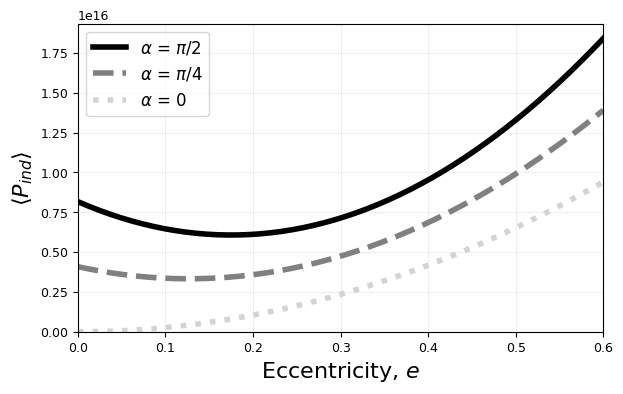

In [172]:
plt.figure(figsize=(onecolwidth, 4))
plt.plot(eccs, ps_ecc_api2, lw=4, color="black", label='$\\alpha$ = $\pi/2$')
plt.plot(eccs, ps_ecc_api4, lw=4, color="gray", ls="--", label='$\\alpha$ = $\pi/4$')
plt.plot(eccs, ps_ecc_a0, lw=4, color="lightgray", ls=":", label='$\\alpha$ = $0$')

#plt.yscale("log")
plt.xlabel("Eccentricity, $e$", fontsize=fontsize)
#plt.ylabel("$\langle P_{ind}  \\rangle $ / $\langle P_{ind, circ}\\rangle$", fontsize=fontsize)
plt.ylabel("$\langle P_{ind}  \\rangle $", fontsize=fontsize)

#plt.plot(eccs, 1+6*eccs**2, "--", lw=4, color="gray")
plt.grid(alpha=0.2)
plt.xlim(0, np.max(eccs))
plt.legend(fontsize=12)

plt.ylim(0)
plt.savefig("pind_ecc.png", dpi=300, bbox_inches="tight")

# Figure 11.

In [ ]:
exo=pd.read_csv("NEA_planets.csv", skiprows=136)

# use default parameters.
exo=exo[exo.default_flag==True]

# eliminate stellar remnants.
exo=exo[exo.st_rad>0.05]

# Eliminate targets for which the host star is not characterized.
exo=exo[exo.st_teff>0]
exo=exo[exo.st_mass>0]

# Narrow our search to planets likely to have thick gaseous envelopes.
exo = exo[exo.pl_radj>0.178]

# Eliminate targets with no orbital period measurement.
exo = exo[exo.pl_orbper>0]

#Eliminate targets with very long orbital periods (GASTLI can struggle with these)
exo = exo[exo.pl_orbper<1000]

# Eliminate objects that are too big.
exo = exo[exo.pl_radj<10]


# categorize host stars w/ temperature and giant/subgiant definition from Stassun+

# Create a column in the array for B_surf.
bsurf = np.zeros(len(exo))

# Giants
bsurf[exo.st_logg.values < 3.5] = 100
# M dwarfs
bsurf[((exo.st_logg.values>=3.5)&(exo.st_teff<4000))]=10000
# Earlier dwarfs
bsurf[((exo.st_logg.values>=3.5)&(exo.st_teff>=4000))]=1000
exo["bsurf"]=bsurf

In [ ]:
# Measure pind for these planets.

mean_pind=np.zeros(len(exo))
for i in tqdm(range(len(exo))):
    ts=np.linspace(0, exo.pl_orbper.values[i]*24*3600)
    pind, _, _, _, _, _ = hf.find_power(ts,
                                fixed_radius=exo.pl_radj.values[i] * hf.RJUP,
                                use_GASTLI=True,
                                p=exo.pl_orbper.values[i], 
                                alpha=np.pi/2, 
                                bsurf=exo.bsurf.values[i],
                                r0=0.0001, 
                                rotper=0.1, 
                                rstar=exo.st_rad.values[i],
                                mstar=exo.st_mass.values[i],
                                tstar=exo.st_teff.values[i], 
                                plot=False,
                                nr=1000)
    mean_pind[i]=np.mean(pind)

exo["pind"]=mean_pind


In [ ]:
type(exo.pl_radj.values[i] * hf.RJUP)

In [ ]:
a = ((exo.pl_orbper/365)**2 * exo.st_mass)**(1/3)
teq = exo.st_teff * np.sqrt(exo.st_rad*hf.RSOLAR/(a*hf.AU)) * (1/4)**(1/4)
dt = (exo.pind/(4*np.pi*hf.SB*(exo.pl_radj*hf.RJUP)**2) + teq**4)**(1/4) - teq
exo["dt"]=dt
exo["teq"]=teq

plt.figure(figsize=(twocolwidth, 6))
exo_mdwarfs=exo[exo.bsurf==10000]
exo_giants=exo[exo.bsurf==100]
exo_earlydwarfs=exo[exo.bsurf==1000]

plt.scatter(exo_mdwarfs.pl_orbper, exo_mdwarfs.pl_radj, c=exo_mdwarfs.dt, marker="s",s=50,norm=matplotlib.colors.LogNorm(vmax=5, vmin=10**-6),zorder=2, label="M Dwarfs", cmap="plasma")

plt.scatter(exo_earlydwarfs.pl_orbper, exo_earlydwarfs.pl_radj, c=exo_earlydwarfs.dt,s=50, norm=matplotlib.colors.LogNorm(vmax=5, vmin=10**-6),zorder=1, label="Other Dwarfs",cmap="plasma")
plt.scatter(exo_giants.pl_orbper, exo_giants.pl_radj, c=exo_giants.dt, marker="*", s=50,norm=matplotlib.colors.LogNorm(vmax=5, vmin=10**-6), zorder=3,label="Giants",cmap="plasma")



plt.xscale("log")
cbar=plt.colorbar()
cbar.set_label("Increase in Surface Temperature, $\delta T$ (K)", fontsize=fontsize)
plt.xlim(0.4, 1*10**3)
plt.ylim(0.178, 3)
plt.legend(fontsize=14)
plt.xlabel("Planet Period (d)", fontsize=fontsize)
plt.ylabel("Planet Radius ($R_J$)", fontsize=fontsize)
plt.grid(alpha=0.2)
plt.savefig("deltaT_rp.png", dpi=300, bbox_inches="tight")

# Table 1.

In [ ]:
df=exo.sort_values("dt", ascending=False)

for i in range(len(df)):
    if df.dt.values[i]>1:
        print(df.pl_name.values[i] + " & {per:.2f} & {rp:.2f} & {rstar:.2f} & {mstar:.2f} & {tstar:.0f} & {teq:.0f} & {pind:.2E} & {dt:.2f} & \\\ ".format(per=df.pl_orbper.values[i],
                                                                                                                                                          rp=df.pl_radj.values[i],
                                                                                                                                                          rstar=df.st_rad.values[i],
                                                                                                                                                          mstar=df.st_mass.values[i],
                                                                                                                                                          tstar=df.st_teff.values[i],
                                                                                                                                                          teq=df.teq.values[i],
                                                                                                                                                          pind=df.pind.values[i],
                                                                                                                                                          dt=df.dt.values[i]))


# Properties of Pulsar planets.

In [ ]:
dfp=pd.read_csv("/home/dawnleaf/Data/from_online/pulsars.csv")
dfp = dfp[dfp["porb(d)"]<30]
radii=np.zeros(len(dfp)) + 3
radii[dfp["mass (MJ)"]<1]=1
radii[dfp["mass (MJ)"]<1/317.8]=0.1
dfp["radii"]=radii


a=(dfp["porb(d)"].values/365)**(2/3)

tstar=10**5 #K
rstar=10000#m

teq=tstar * np.sqrt(rstar/(a*hf.AU))*(1/4)**(1/4)
dfp["teq"]=teq



pind_pul, dt_pul, teq_pul = np.zeros(len(dfp)), np.zeros(len(dfp)), np.zeros(len(dfp))

nt=300

for i in tqdm(range(len(dfp))):
    ts=np.linspace(0, dfp["porb(d)"].values[i]*24*3600, nt)

    pind_pulsar, _, _, _, _, _ = hf.find_power(ts,
                                fixed_radius=dfp.radii.values[i]* hf.RJUP,
                                use_GASTLI=True,
                                p=dfp["porb(d)"].values[i], 
                                alpha=np.pi/2, 
                                bsurf=10**10,
                                r0=0.0001, 
                                rotper=dfp["prot (s)"].values[i]/24/3600, 
                                rstar=rstar/hf.RSOLAR,
                                mstar=1,
                                tstar=tstar, 
                                plot=False,
                                nr=1000)
    pind_pul[i] = np.mean(pind_pulsar)

In [ ]:
dt = (pind_pul/(4*np.pi*hf.SB*(dfp.radii*hf.RJUP)**2) + teq**4)**(1/4) - teq
dfp["dt"]=dt
dfp["pind"]=pind_pul

In [ ]:
dfp

# Figure 12.

In [ ]:
# WD 1856 system

from uncertainties import ufloat

n=1000
rstar=ufloat(0.0121,0.0002)*hf.RSOLAR
tstar=ufloat(4920,50)
pstar=ufloat(1.407939217,0.000000016 )
mstar= ufloat(0.605,0.013)
rplanet=ufloat(0.946, 0.017)*hf.RJUP


a = ((pstar/365)**2 * mstar)**(1/3) * hf.AU
albedo=0.0
teq = tstar*(1-albedo)**(1/4) * (rstar/(2*a))**(1/2)

rp_wd, tprofile_wd, pprofile_wd = hf.generate_profile(teq=teq.n, fixed_radius=rplanet.n)



In [ ]:

ts=np.linspace(0, pstar.n*24*3600, 3000)
pinds_wd, _, _, _, _, _ = hf.find_power(ts,use_GASTLI=True, fixed_radius=rplanet.n, p=pstar.n, alpha=np.pi/2, bsurf=10**9,r0=0.0001, mstar=mstar.n, tstar=tstar.n, rstar=rstar.n/hf.RSOLAR, rotper=0.08, nr=1000, pregen_r=rp_wd, pregen_tprofile=tprofile_wd, pregen_pprofile=pprofile_wd)


tsurf = (np.mean(pinds_wd)/(4*np.pi*hf.SB*rplanet**2) + teq**4)**(1/4)
print("Tsurf = {tsurf:.0f}; Teq = {teq:.0f}".format(tsurf=tsurf, teq=teq))


In [ ]:
bsurfs=np.logspace(6, 9, 20, base=10)
alphas=np.linspace(0, np.pi/2, 20)
rotpers = np.array([0.1, 1.4, 100])

pind_wds = np.zeros((len(bsurfs), len(alphas), len(rotpers)))
tsurf_wds = np.zeros((len(bsurfs), len(alphas), len(rotpers)))
bsurf_wds= np.zeros((len(bsurfs), len(alphas), len(rotpers)))
alpha_wds= np.zeros((len(bsurfs), len(alphas), len(rotpers)))
rotper_wds= np.zeros((len(bsurfs), len(alphas), len(rotpers)))


for i in tqdm(range(len(bsurfs))):
    bsurf=bsurfs[i]
    for j in range(len(alphas)):
        alpha=alphas[j]
        for k in range(len(rotpers)):
            rotper = rotpers[k]
            pinds_wd, _, _, _, _, _ = hf.find_power(ts,use_GASTLI=True, fixed_radius=rplanet.n, p=pstar.n, alpha=alpha, bsurf=bsurf,r0=0.0001, mstar=mstar.n, tstar=tstar.n, rstar=rstar.n/hf.RSOLAR, rotper=0.08, nr=1000, pregen_r=rp_wd, pregen_tprofile=tprofile_wd, pregen_pprofile=pprofile_wd)

            pind_wds[i][j][k]=np.mean(pinds_wd)
            tsurf_wds[i][j][k] = ((pind_wds[i][j][k]/(4*np.pi*hf.SB*rplanet**2) + teq**4)**(1/4)-teq).n
            bsurf_wds[i][j][k]=bsurf
            alpha_wds[i][j][k]=alpha
            rotper_wds[i][j][k]=rotper

In [ ]:
fig, axs=plt.subplots(1,3, sharex=True, sharey=True, figsize=(twocolwidth, 6))
import matplotlib.cm as cm
for i in range(len(rotpers)):

    a = axs[i].pcolor(alpha_wds[:, :, i], np.log10(bsurf_wds[:, :, i]), tsurf_wds[:, :, i], shading="nearest", vmin=0, vmax=100, cmap=cm.bone)#,norm=matplotlib.colors.LogNorm(vmin=0.01, vmax=1000))
    axs[i].set_title("$p_{{rot}}$ = {f:.1f} d".format(f=rotpers[i]), fontsize=fontsize)
fig.text(0.44, 0.00, "Orbital Misalignment, $\\alpha$ (Radians)", ha='center', fontsize=fontsize)
axs[0].set_ylabel("log$_{10}(B_{surf})$ (G)", fontsize=fontsize)

cbar=fig.colorbar(a, ax=axs)
cbar.set_label("Increase in Surface Temperature, $\delta$T (K)", fontsize=fontsize)
#plt.subplots_adjust(wspace=0.07)
plt.savefig("WD_temp_changes.png", dpi=300, bbox_inches="tight")

# Nonzero obliquity.

In [ ]:
lams = np.linspace(-np.pi, np.pi, 50)
ps_lam=np.zeros(len(lams))
ps_alph_p15=np.zeros(len(lams))
ps_alph_p1=np.zeros(len(lams))
ps_alph_p2=np.zeros(len(lams))

ts = np.linspace(0, porb_default*24*3600)

for i in tqdm(range(len(lams))):
    pinds_l, _, _, _, _, _= hf.find_power_lambda_zeroalpha(ts, p=porb_default, lam=lams[i], bsurf=bsurf_default, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile)
    ps_lam[i]=np.mean(pinds_l)


for i in tqdm(range(len(lams))):
    pinds_a, _, _, _, _, _= hf.find_power(ts, p=porb_default, alpha=lams[i], bsurf=bsurf_default, rotper=1.5, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile)
    ps_alph_p15[i]=np.mean(pinds_a)

for i in tqdm(range(len(lams))):
    pinds_a, _, _, _, _, _= hf.find_power(ts, p=porb_default, alpha=lams[i], bsurf=bsurf_default, rotper=1, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile)
    ps_alph_p1[i]=np.mean(pinds_a)

for i in tqdm(range(len(lams))):
    pinds_a, _, _, _, _, _= hf.find_power(ts, p=porb_default, alpha=lams[i], bsurf=bsurf_default, rotper=2, fixed_radius=rp_default, use_GASTLI=True, pregen_r=rp, pregen_tprofile=tprofile, pregen_pprofile=pprofile)
    ps_alph_p2[i]=np.mean(pinds_a)


In [ ]:
plt.figure(figsize=(onecolwidth, 4))

plt.plot(lams, ps_lam, color="black", lw=4, label="$\lambda, \\alpha=0$")
plt.plot(lams, ps_alph_p15, ls=":", label="$\\alpha, \lambda=0, \\omega=\\omega_p$", color="cornflowerblue", lw=4)
plt.plot(lams, ps_alph_p1, ls="-.", label="$\\alpha, \lambda=0, \\omega=2\\omega_p$", color="tomato", lw=4)
plt.plot(lams, ps_alph_p2, ls="--", label="$\\alpha, \lambda=0, \\omega=\\frac{1}{2}\\omega_p$", color="goldenrod", lw=4)
plt.legend()
plt.xlabel("Angle (Radians)", fontsize=fontsize)
plt.ylabel("Average Power, $\langle P_{ind} \\rangle$ (J/s)", fontsize=fontsize)
plt.grid(alpha=0.2)
plt.xlim(-np.pi, np.pi)
plt.ylim(0)
plt.savefig("angle_power.png", dpi=300, bbox_inches="tight")